# **1 Obtenção de Credenciais e escolha de fonte de dados**

In [ ]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
TOKEN = "dce69618b1fbb73b5915bf30686c5db2"

url = "https://apidadosabertos.saude.gov.br/assistencia-a-saude/unidade-basicas-de-saude"

headers = {
    "chave-api-dados": TOKEN
}

params = {
    "limit": 100,
    "offset": 0
}

In [ ]:
response = requests.get(url, headers=headers, params=params)
print(response.status_code)


200


In [ ]:
dados = response.json()

print(type(dados))
print(dados)

<class 'dict'>
{'ubs': [{'ibge': '260290', 'bairro': 'PONTE DOS CARVALHOS', 'logradouro': 'RUA DO CEMITERIO', 'cnes': '0000302', 'uf': '26', 'latitude': '-8,21811', 'longitude': '-35,22944', 'nome': 'USF SANTO ESTEVAO'}, {'ibge': '500240', 'bairro': 'SANTO ANTONIO', 'logradouro': 'RUA JOAO PESSOA', 'cnes': '2376210', 'uf': '50', 'latitude': '-22,61912', 'longitude': '-54,83528', 'nome': 'ESTRATEGIA DE SAUDE DA FAMILIA MARIZA RODRIGUES DOS SANTOS'}, {'ibge': '355030', 'bairro': 'GUAIANASES', 'logradouro': 'RUA CHUVAS DE VERAO', 'cnes': '2789310', 'uf': '35', 'latitude': '-23,56096', 'longitude': '-46,42381', 'nome': 'UBS VILA COSMOPOLITA'}, {'ibge': '211060', 'bairro': 'ZONA RURAL', 'logradouro': 'POVOADO MORRO DO SALTO DA PEDRA', 'cnes': '4613902', 'uf': '21', 'latitude': '-3,42166', 'longitude': '-42,36826', 'nome': 'POSTO MORRO DO SALTO DA PEDRA'}, {'ibge': '211060', 'bairro': 'ZONA RURAL', 'logradouro': 'POVOADO ENXU', 'cnes': '4613910', 'uf': '21', 'latitude': '-3,32356', 'longitud

# **2 DataFrame**

In [ ]:
dados = response.json()

df = pd.DataFrame(dados["ubs"])

df.head()

,ibge,bairro,logradouro,cnes,uf,latitude,longitude,nome
0,260290,PONTE DOS CARVALHOS,RUA DO CEMITERIO,0000302,26,"-8,21811","-35,22944",USF SANTO ESTEVAO
1,500240,SANTO ANTONIO,RUA JOAO PESSOA,2376210,50,"-22,61912","-54,83528",ESTRATEGIA DE SAUDE DA FAMILIA MARIZA RODRIGUE...
2,355030,GUAIANASES,RUA CHUVAS DE VERAO,2789310,35,"-23,56096","-46,42381",UBS VILA COSMOPOLITA
3,211060,ZONA RURAL,POVOADO MORRO DO SALTO DA PEDRA,4613902,21,"-3,42166","-42,36826",POSTO MORRO DO SALTO DA PEDRA
4,211060,ZONA RURAL,POVOADO ENXU,4613910,21,"-3,32356","-42,58953",POSTO ENXU


# **3 Limpeza de dados**

In [ ]:
df = df.dropna()
df = df.drop_duplicates()
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 97 entries, 0 to 99
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   ibge        97 non-null     object
 1   bairro      97 non-null     object
 2   logradouro  97 non-null     object
 3   cnes        97 non-null     object
 4   uf          97 non-null     object
 5   latitude    97 non-null     object
 6   longitude   97 non-null     object
 7   nome        97 non-null     object
dtypes: object(8)
memory usage: 6.8+ KB


**so de santa catarina**

In [ ]:
df_sc = df[df["uf"] == "42"]

df_sc.head()

,ibge,bairro,logradouro,cnes,uf,latitude,longitude,nome
62,420245,SERTAOZINHO,AVENIDA ARACA,4657659,42,"-27,17071","-48,52087",UNIDADE DE SAUDE DE SERTAOZINHO
84,421950,BORTOLON,ANTONIO VITORIO GIORDANI,4672208,42,"-26,877","-52,404",UNIDADE SANITARIA BORTOLON I


In [ ]:
bairro_counts = df["bairro"].value_counts()

bairro_counts.head(10)

,count
bairro,
CENTRO,11
ZONA RURAL,8
PONTE DOS CARVALHOS,6
RURAL,2
SANTO ANTONIO,1
GUAIANASES,1
JARDIM MARINGA,1
P A WALTER ARCE,1
CHAPADA DO MEIO,1


# **4 Graficos**

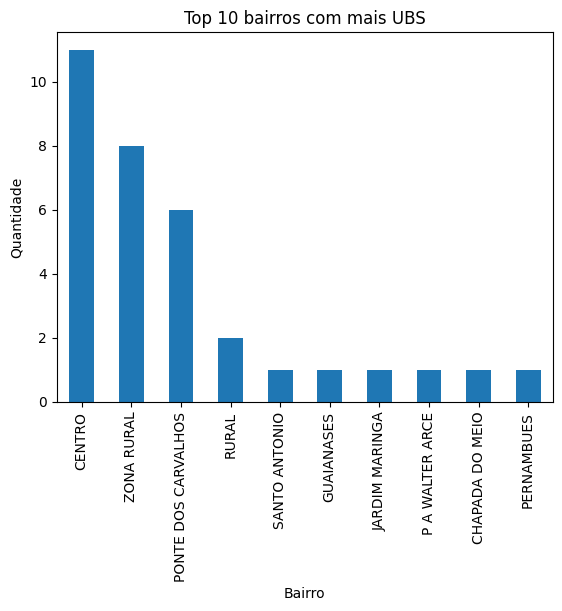

In [ ]:
bairro_counts.head(10).plot(kind="bar")

plt.title("Top 10 bairros com mais UBS")

plt.xlabel("Bairro")

plt.ylabel("Quantidade")

plt.show()

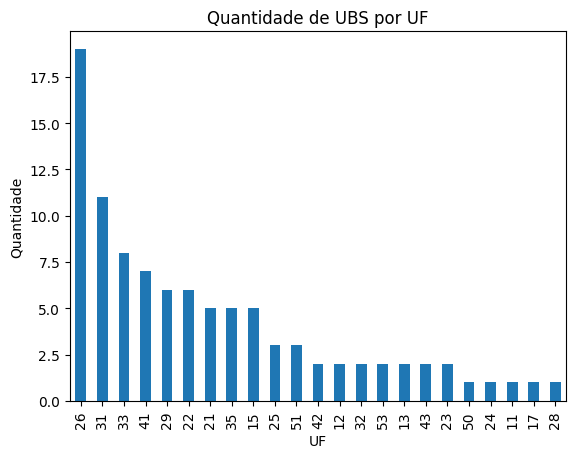

In [ ]:
uf_counts = df["uf"].value_counts()

uf_counts.plot(kind="bar")

plt.title("Quantidade de UBS por UF")

plt.xlabel("UF")

plt.ylabel("Quantidade")

plt.show()

In [ ]:
df.to_csv("ubs.csv", index=False)